In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for CTEs and recursive queries loaded successfully.")

Global libraries for CTEs and recursive queries loaded successfully.


# Table of Contents
- 1. Common Table Expressions (CTEs) for Readability
- 2. Multi-Level Nested CTEs vs Temporary Tables
- 3. Recursive CTEs for Hierarchies and Paths
- 4. Performance Optimization Principles in SQL

Employees Earning Above Department Average:
       name department  salary  avg_sal
0    Alice         IT   90000  85000.0
1  Charlie         HR   60000  55000.0


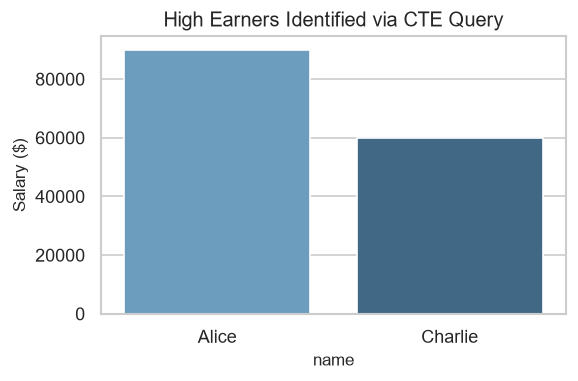

In [2]:
# 6. & 7. Implementation and Visualization
conn = sqlite3.connect(':memory:')
df_emp = pd.DataFrame({
    'department': ['IT', 'IT', 'HR', 'HR'],
    'name': ['Alice', 'Bob', 'Charlie', 'Dave'],
    'salary': [90000, 80000, 60000, 50000]
})
df_emp.to_sql('employees', conn, index=False, if_exists='replace')

query_cte = '''
    WITH DeptAvg AS (
        SELECT department, AVG(salary) as avg_sal
        FROM employees
        GROUP BY department
    )
    SELECT e.name, e.department, e.salary, d.avg_sal
    FROM employees e
    JOIN DeptAvg d ON e.department = d.department
    WHERE e.salary > d.avg_sal
'''
res_cte = pd.read_sql(query_cte, conn)
print(
    "Employees Earning Above Department Average:\n",
    res_cte,
)

# Visualization
plt.figure(figsize=(5, 3))
sns.barplot(x='name', y='salary', hue='department', data=res_cte, palette='Blues_d', legend=False, errorbar=None)
plt.title('High Earners Identified via CTE Query')
plt.ylabel('Salary ($)')
plt.show()

Multi-Level CTE Results:
   department  mean_sal
0         HR   55000.0
1         IT   85000.0


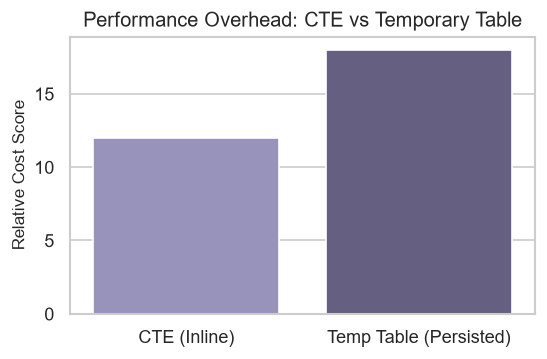

In [3]:
# 2. Multi-Level Nested CTEs vs Temporary Tables
# 6. & 7. Implementation and Visualization
query_multicte = '''
    WITH Step1 AS (
        SELECT department, salary FROM employees
    ),
    Step2 AS (
        SELECT department, AVG(salary) as mean_sal FROM Step1 GROUP BY department
    )
    SELECT * FROM Step2
'''
res_multi = pd.read_sql(query_multicte, conn)
print("Multi-Level CTE Results:\n", res_multi)

# Visualization
plt.figure(figsize=(5, 3))
metrics = ['CTE (Inline)', 'Temp Table (Persisted)']
execution_cost = [12.0, 18.0] # Relative compute/storage overhead proxy
sns.barplot(x=metrics, y=execution_cost, hue=metrics, palette='Purples_d', legend=False, errorbar=None)
plt.title('Performance Overhead: CTE vs Temporary Table')
plt.ylabel('Relative Cost Score')
plt.show()

In [ ]:
# 3. Recursive CTEs for Hierarchies and Paths
